In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.random import random

# Data Sources, Preparation, & Cleaning

In [ ]:
# Load the ULB credit card dataset
path = '/content/drive/MyDrive/Datafiles/creditcard.csv'
df = pd.read_csv(path)

print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# Load IEEE-CIS (two training tables) from Drive
folder = '/content/drive/MyDrive/Datafiles/'

trans = pd.read_csv(folder + 'train_transaction.csv')
iden  = pd.read_csv(folder + 'train_identity.csv')

# Join on TransactionID, keeping every transaction
ieee = trans.merge(iden, on='TransactionID', how='left')

print("Transactions:", trans.shape)
print("Identity:    ", iden.shape)
print("Merged:      ", ieee.shape)

Transactions: (590540, 394)
Identity:     (144233, 41)
Merged:       (590540, 434)


In [ ]:
# ULB: any missing values?
print("Total missing:", df.isnull().sum().sum())
print()
print(df.isnull().sum())

Total missing: 0

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [ ]:
# ULB: look for duplicates rows
flaggedDuplicates = df.duplicated(keep=False)   # all rows that repeat
extraCopies = df.duplicated()                   # just the extra copies

print(f"Rows involved in duplication: {flaggedDuplicates.sum()}")
print(f"Extra copies (to drop):       {extraCopies.sum()}")
print()
print("Extra copies by class:")
print(df.loc[extraCopies, "Class"].value_counts())

Rows involved in duplication: 1854
Extra copies (to drop):       1081

Extra copies by class:
Class
0    1062
1      19
Name: count, dtype: int64


In [ ]:
# ULB: remove the duplicates
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After: ", df.shape)
print()

# ULB: check fraud count after
print("Class counts after cleaning:")
print(df["Class"].value_counts())
print(f"\nFraud rate: {df['Class'].mean()*100:.3f}%")

df_clean = df

Before: (284807, 31)
After:  (283726, 31)

Class counts after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate: 0.167%


In [ ]:
# IEEE: first look
print(f"Fraud rate: {ieee['isFraud'].mean()*100:.2f}%")
print(f"Duplicate IDs: {ieee['TransactionID'].duplicated().sum()}")
print()

# IEEE: how many have device info
has_id = ieee['TransactionID'].isin(iden['TransactionID'])
print(f"With identity info: {has_id.mean()*100:.1f}%")
print()

# IEEE: fraud with vs without device info
print("Fraud rate by identity info:")
print((ieee.groupby(has_id)['isFraud'].mean()*100).round(2)
      .rename({True: 'Has identity', False: 'No identity'}))
print()

# IEEE: how much is missing
miss = ieee.isnull().mean()*100
print(f"Columns with missing: {(miss > 0).sum()} of {ieee.shape[1]}")
print(f"Over 50% missing: {(miss > 50).sum()}")
print(f"Over 90% missing: {(miss > 90).sum()}")

Fraud rate: 3.50%
Duplicate IDs: 0

With identity info: 24.4%

Fraud rate by identity info:
TransactionID
No identity     2.09
Has identity    7.85
Name: isFraud, dtype: float64

Columns with missing: 414 of 434
Over 50% missing: 214
Over 90% missing: 12


In [ ]:
# IEEE: drop columns that are almost empty
drop_cols = miss[miss > 90].index.tolist()
print("Dropping:", drop_cols)

ieee_clean = ieee.drop(columns=drop_cols)

# IEEE: 1 if it has device info, 0 if not
ieee_clean['has_identity'] = has_id.astype(int)

print()
print("Before:", ieee.shape)
print("After: ", ieee_clean.shape)

Dropping: ['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']

Before: (590540, 434)
After:  (590540, 423)


In [ ]:
import textwrap

# summary of the cleaned datasets
for name, data in [('ULB Credit Card (creditcard.csv)', df),
                   ('IEEE-CIS (train_transaction + train_identity)', ieee_clean)]:
    cols = list(data.columns)
    shown = cols if len(cols) <= 40 else cols[:40]
    text = ', '.join(f'{i+1}:{c}' for i, c in enumerate(shown))
    if len(cols) > 40:
        text += f', ... (+{len(cols) - 40} more columns)'

    print('+' * 90)
    print('DATASET:', name)
    print('Shape:', data.shape)
    print('Columns:')
    print(textwrap.fill(text, width=90))
print('+' * 90)

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
DATASET: ULB Credit Card (creditcard.csv)
Shape: (283726, 31)
Columns:
1:Time, 2:V1, 3:V2, 4:V3, 5:V4, 6:V5, 7:V6, 8:V7, 9:V8, 10:V9, 11:V10, 12:V11, 13:V12,
14:V13, 15:V14, 16:V15, 17:V16, 18:V17, 19:V18, 20:V19, 21:V20, 22:V21, 23:V22, 24:V23,
25:V24, 26:V25, 27:V26, 28:V27, 29:V28, 30:Amount, 31:Class
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
DATASET: IEEE-CIS (train_transaction + train_identity)
Shape: (590540, 423)
Columns:
1:TransactionID, 2:isFraud, 3:TransactionDT, 4:TransactionAmt, 5:ProductCD, 6:card1,
7:card2, 8:card3, 9:card4, 10:card5, 11:card6, 12:addr1, 13:addr2, 14:dist1,
15:P_emaildomain, 16:R_emaildomain, 17:C1, 18:C2, 19:C3, 20:C4, 21:C5, 22:C6, 23:C7,
24:C8, 25:C9, 26:C10, 27:C11, 28:C12, 29:C13, 30:C14, 31:D1, 32:D2, 33:D3, 34:D4, 35:D5,
36:D6, 37:D8, 38:D9, 39:D10, 40:D11, ... (+383 more columns)
++++++++++++++++++++++++++++++

# Exploratory Data Analysis (EDA)

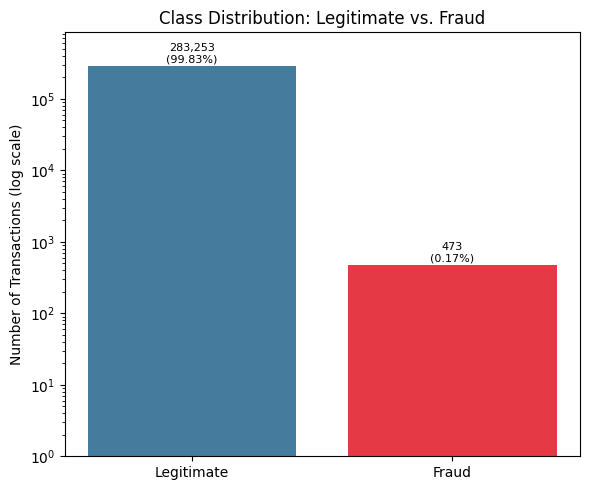

In [ ]:
# Class distribution barchart - Violet
totalFraud = int(df_clean['Class'].sum())
totalLegit = len(df_clean) - totalFraud

plt.figure(figsize = (6, 5))
barchart = plt.bar(["Legitimate", "Fraud"], [totalLegit, totalFraud], color = ["#457b9d", "#e63946"])
plt.yscale("log")
plt.ylabel("Number of Transactions (log scale)")
plt.ylim(1, totalLegit * 3)
plt.title("Class Distribution: Legitimate vs. Fraud")
for barchart, count in zip(barchart, [totalLegit, totalFraud]):
    plt.text(barchart.get_x() + barchart.get_width() / 2, barchart.get_height() * 1.5,
              f"{count:,}\n({count / len(df_clean) * 100:.2f}%)",
              ha = "center", va = "center", fontsize = 8)
plt.tight_layout()
plt.show()

# Figure Description/Insights:
# Barchart showing percentages of fraud & legitimate transactions in the dataset (log scale to visualize the difference better).
# Extreme class imbalance (99.83% legitimate vs. 0.17% fraud).
# Model predicting "not fraud" everytime would be 99.8% accurate while catching no fraud.
# Instead, use precision/recall at fixed recall thresholds.

Class
0    25691.16
1     2125.87
Name: Amount, dtype: float64


,mean,median
Class,,
0,88.413575,22.00
1,123.871860,9.82


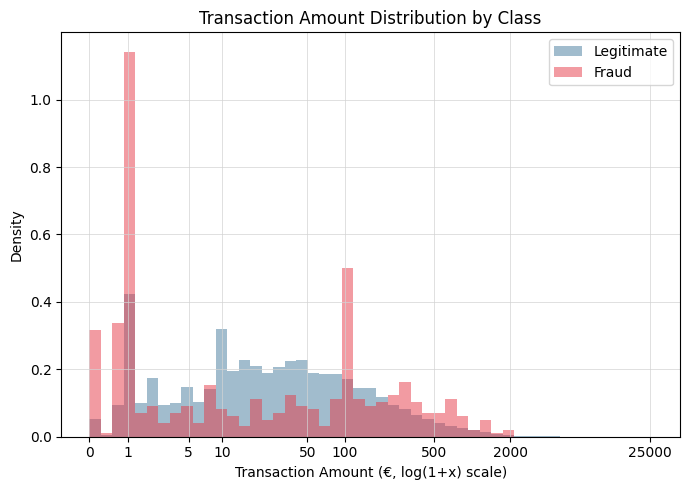

In [ ]:
# Amount distribution by class histogram - Violet
log1pAmount = np.log1p(df_clean["Amount"])
bins = np.linspace(log1pAmount.min(), log1pAmount.max())

plt.figure(figsize = (7, 5))
plt.hist(log1pAmount[df_clean.Class == 0], bins = bins, color = "#457b9d", alpha = 0.5, label = "Legitimate", density = True)
plt.hist(log1pAmount[df_clean.Class == 1], bins = bins, color = "#e63946", alpha = 0.5, label = "Fraud", density = True)
xTicks = [0, 1, 5, 10, 50, 100, 500, 2000, 25000]
plt.xticks(np.log1p(xTicks), [str(n) for n in xTicks])
plt.xlabel("Transaction Amount (\u20ac, log(1+x) scale)")
plt.ylabel("Density")
plt.title("Transaction Amount Distribution by Class")
plt.legend()
plt.grid(True, color = "lightgray", linewidth = 0.5)
plt.tight_layout()

print(df_clean.groupby("Class")["Amount"].max()) # Max transaction amount is >€25000 (hard to visualize on graph)
df.groupby("Class")["Amount"].agg(["mean", "median"]) # Average & median for both classes

# Figure Description/Insights:
# Histogram of transaction amount differences for each class.
# Legitimate transactions average amount is €88.41 & median is €22.00.
# Fraudulent transactions average amount is €123.87 & median is €9.82.
# Fraud disproportionately concentrated at €1 (card testing to see if a stolen card is still active).
# Second smaller concentration around €100.

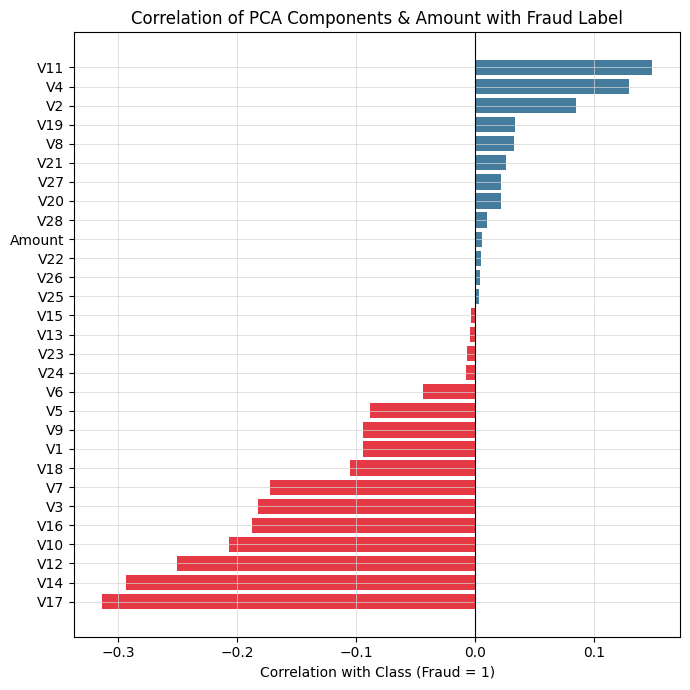

In [ ]:
# Correlation of each feacture with class barchart - Violet
vCols = [f for f in df_clean.columns if f.startswith("V")] + ["Amount"]
corr = df_clean[vCols + ["Class"]].corr()["Class"].drop("Class").sort_values()

plt.figure(figsize = (7, 7))
color = ["#e63946" if v < 0 else "#457b9d" for v in corr.values]
plt.barh(corr.index, corr.values, color = color)
plt.axvline(0, color = "black", linewidth = 0.8)
plt.xlabel("Correlation with Class (Fraud = 1)")
plt.title("Correlation of PCA Components & Amount with Fraud Label")
plt.tight_layout()
plt.grid(True, color = "lightgray", linewidth = 0.5)
plt.show()

# Figure Description/Insights:
# Barchart ranking each PCA component's (V1-V28) & Amount's linear correlation with fraud.
# V11, V4, & V2 have the strongest positive correlation with fraud.
# V17, V14, & V12 have the strongest negative correlation with fraud.
# Amount's correlation with fraud is near zero (0.006).

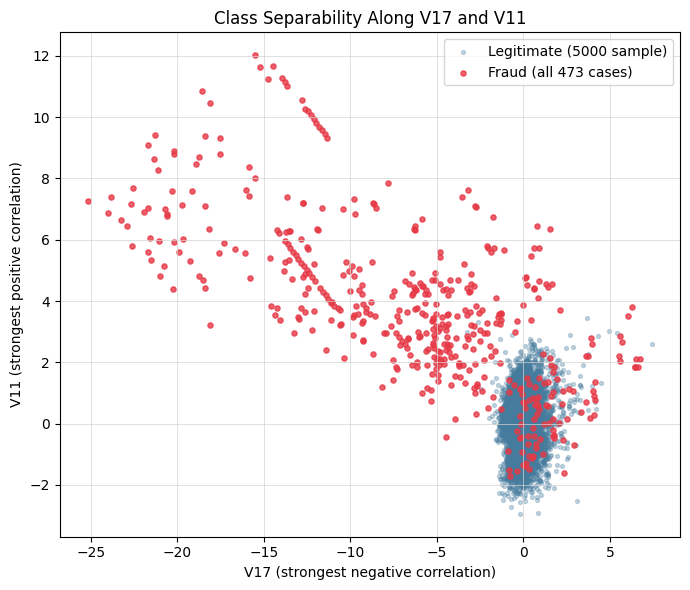

In [ ]:
# Class separability of two most correlated features (V11 & V17) scatterplot - Violet
vCols = [f for f in df.columns if f.startswith("V")] + ["Amount"]
corr = df_clean[vCols + ["Class"]].corr()["Class"].drop("Class").sort_values()
legitSample = df_clean[df_clean.Class == 0].sample(n = 5000, random_state = 42)
fraudSample = df_clean[df_clean.Class == 1]

plt.figure(figsize = (7, 6))
plt.scatter(legitSample[corr.idxmin()], legitSample[corr.idxmax()], color = "#457b9d", label = "Legitimate (5000 sample)", s = 8, alpha = 0.3)
plt.scatter(fraudSample[corr.idxmin()], fraudSample[corr.idxmax()], color = "#e63946", label = "Fraud (all 473 cases)", s = 14, alpha = 0.8)
plt.xlabel("V17 (strongest negative correlation)")
plt.ylabel("V11 (strongest positive correlation)")
plt.title("Class Separability Along V17 and V11")
plt.legend()
plt.tight_layout()
plt.grid(True, color = "lightgray", linewidth = 0.5)
plt.show()

# Figure Description/Insights:
# Scatterplot of individual transactions along the two most class-correlated components (V17 & V11).
# Fraud & legitimate separate substantially, but overlap in the bottom-right region
# Informative features alone cannot cleanly separate the two classes (use ensemble methods to combine many features rather than relying on one).

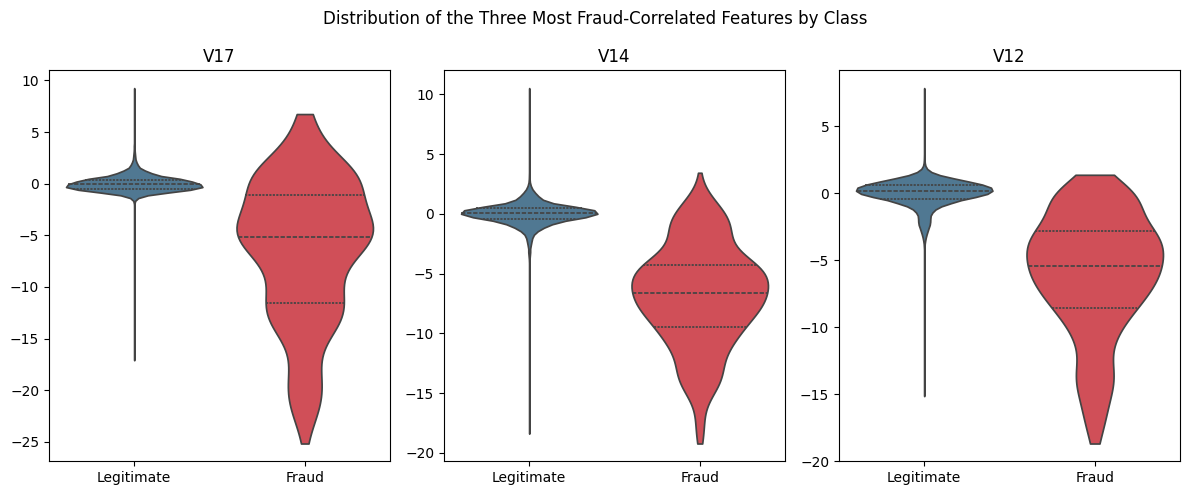

In [ ]:
# Distribution of top three fraud-correlated features by class violinplot - Violet
topThree = ["V17", "V14", "V12"]
plt.figure(figsize = (12, 5))
for i, feature in enumerate(topThree):
    plt.subplot(1, 3, i + 1)
    sns.violinplot(x = "Class", y = feature, data = df_clean, palette = ["#457b9d", "#e63946"], hue = "Class", inner = "quartile", cut = 0, legend = False)
    plt.xticks([0, 1], ["Legitimate", "Fraud"])
    plt.xlabel("")
    plt.ylabel("")
    plt.title(feature)
plt.suptitle("Distribution of the Three Most Fraud-Correlated Features by Class")
plt.tight_layout()
plt.show()

# Figure Description/Insights:
# Violin plots showing full distribution of V17, V14, & V12 for both classes.
# Legitimate medians sit around 0.
# Fraud medians are significantly lower (around -5) with a wider spread & long lower tails.
# Features have different fraud distributions (not all fraud looks alike).
# Legitimate transactions have thin tails going as far down as fraud (using a single feature would produce false positives).

Overall fraud rate: 0.1667


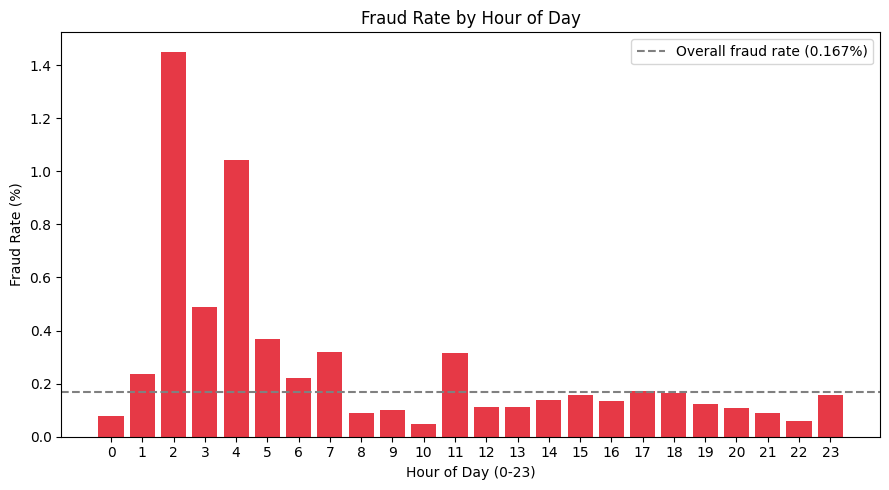

In [ ]:
# Fraud rate by hour of day barchart - Violet
df_clean["HourOfDay"] = (df_clean["Time"] % 86400) // 3600
hourRate = df_clean.groupby("HourOfDay")["Class"].mean() * 100
overallRate = df_clean["Class"].mean() * 100
print(f"Overall fraud rate: {overallRate:.4f}")

plt.figure(figsize = (9, 5))
plt.bar(hourRate.index, hourRate.values, color = "#e63946")
plt.axhline(overallRate, color = "grey", linestyle = "--", label = "Overall fraud rate (0.167%)")
plt.xticks(range(24))
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour of Day")
plt.legend()
plt.tight_layout()
plt.show()

# Figure Description/Insights:
# Barchart of percent of transactions that are fraud each hour.
# Hour 2 has the highest fraud rate (1.45%) & hour 4 has 1.04%
# Most daytime hours sit at or below the average rate (0.05%-0.17%).
# Hour 11 has second highest number of fraud (53 cases) but only a 0.32% rate since it is one of the busiest times (>16000 transactions).
# Overnight hours (2-5) are our fraud risk window, hour 11 spiking is mostly due to volume of transactions.
# Hours are relative to the dataset's internal clock & might not match local time.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_score, recall_score, f1_score)

X = df_clean.drop(columns=["Class", "Time"])
y = df_clean["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, stratify = y, random_state = 42)

rf_model = RandomForestClassifier(n_estimators=300, class_weight = "balanced", random_state = 42, n_jobs = -1)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("AUPRC:", average_precision_score(y_test, y_prob))

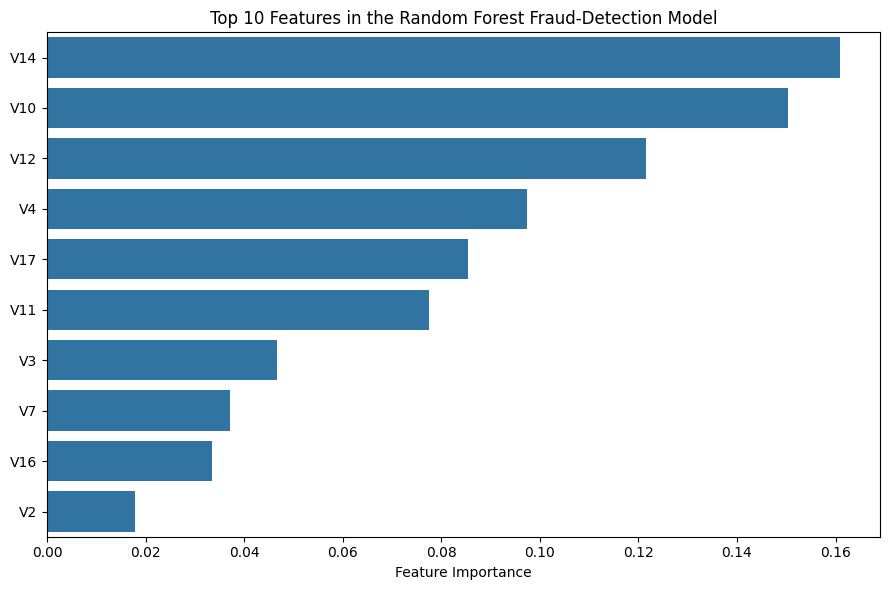

In [ ]:
importance_df = pd.DataFrame({"Feature": X_train.columns, "Importance": rf_model.feature_importances_})
importance_df = (importance_df.sort_values("Importance", ascending=False).head(10))

plt.figure(figsize=(9, 6))
sns.barplot(data = importance_df, x = "Importance", y = "Feature")
plt.title("Top 10 Features in the Random Forest Fraud-Detection Model")
plt.xlabel("Feature Importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

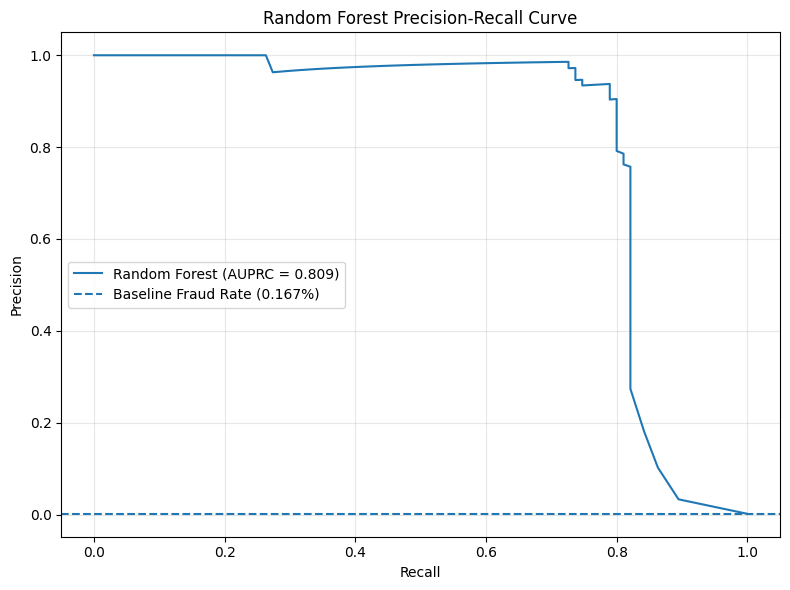

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
auprc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label = f"Random Forest (AUPRC = {auprc:.3f})")

baseline = y_test.mean()
plt.axhline(baseline, linestyle = "--", label = f"Baseline Fraud Rate ({baseline:.3%})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

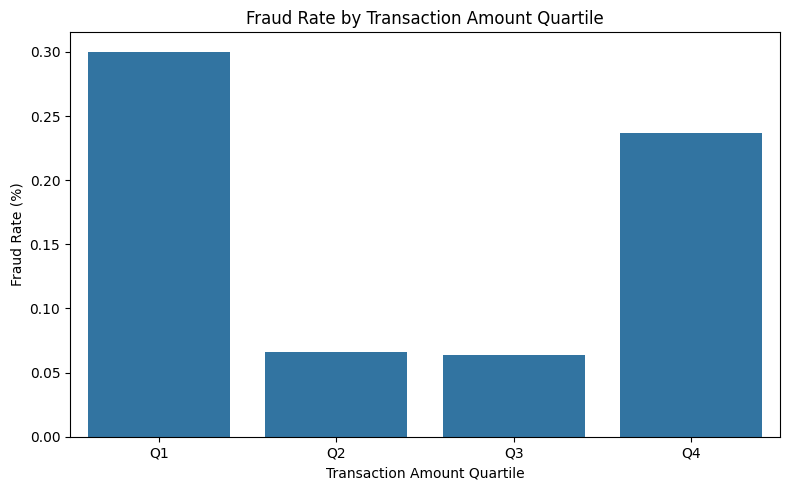

In [ ]:
#Ishita Plot 2- Fraud Rate by Transaction amount Quartile

df["Amount_Quartile"] = pd.qcut(
    df["Amount"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

quartile_fraud = (
    df.groupby("Amount_Quartile", observed=False)["Class"]
    .mean() * 100
)

plt.figure(figsize=(8, 5))
sns.barplot(x=quartile_fraud.index, y=quartile_fraud.values)

plt.title("Fraud Rate by Transaction Amount Quartile")
plt.xlabel("Transaction Amount Quartile")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

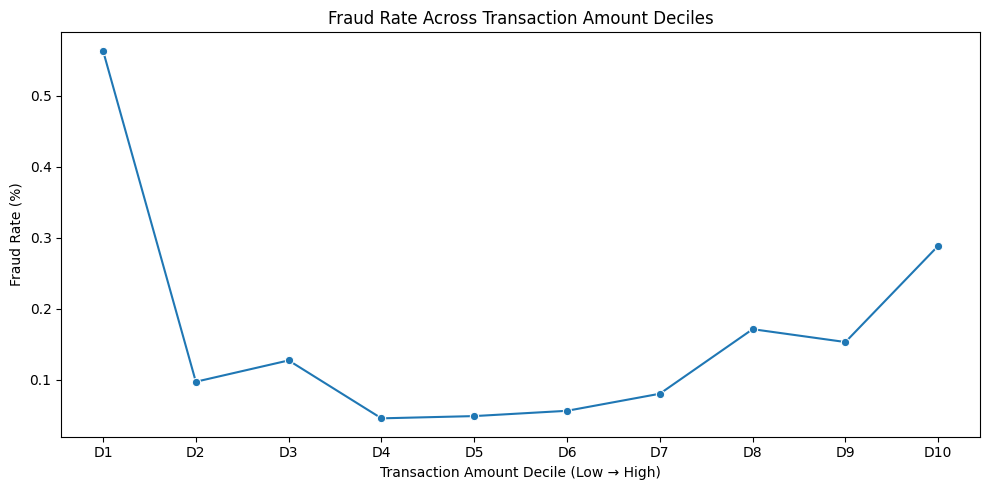

In [ ]:
#Ishita Plot 5- Fraud rate by transaction amount decile
df["Amount_Decile"] = pd.qcut(
    df["Amount"],
    q=10,
    duplicates="drop"
)

decile_fraud = (
    df.groupby("Amount_Decile", observed=False)["Class"]
    .mean()
    .mul(100)
    .reset_index()
)

decile_fraud["Decile"] = [
    f"D{i+1}" for i in range(len(decile_fraud))
]

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=decile_fraud,
    x="Decile",
    y="Class",
    marker="o"
)

plt.title("Fraud Rate Across Transaction Amount Deciles")
plt.xlabel("Transaction Amount Decile (Low → High)")
plt.ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

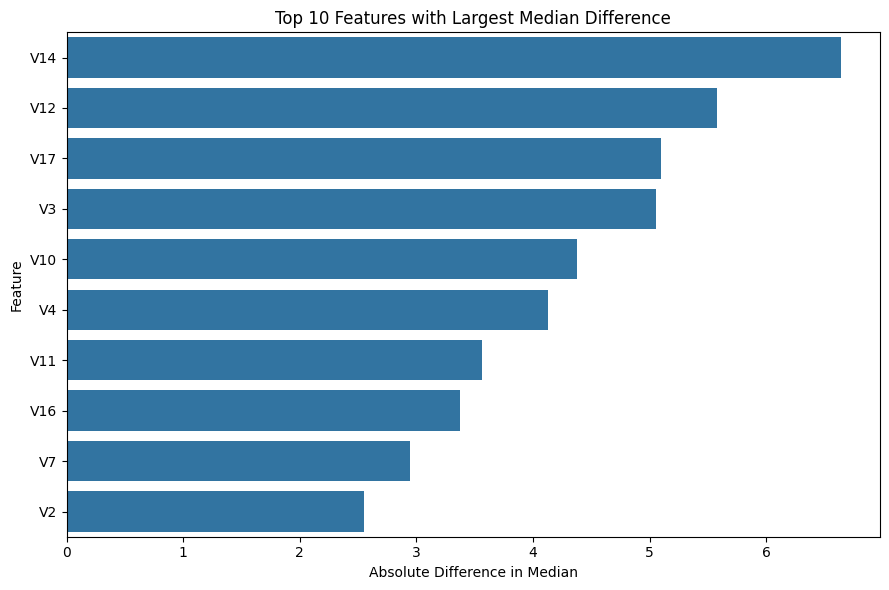

In [ ]:
#Ishita Plot 7- Features with Largest Median Difference

v_columns = [f"V{i}" for i in range(1, 29)]

legit_median = df[df["Class"] == 0][v_columns].median()
fraud_median = df[df["Class"] == 1][v_columns].median()

median_difference = (
    fraud_median - legit_median
).abs().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=median_difference.values,
    y=median_difference.index
)

plt.title("Top 10 Features with Largest Median Difference")
plt.xlabel("Absolute Difference in Median")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

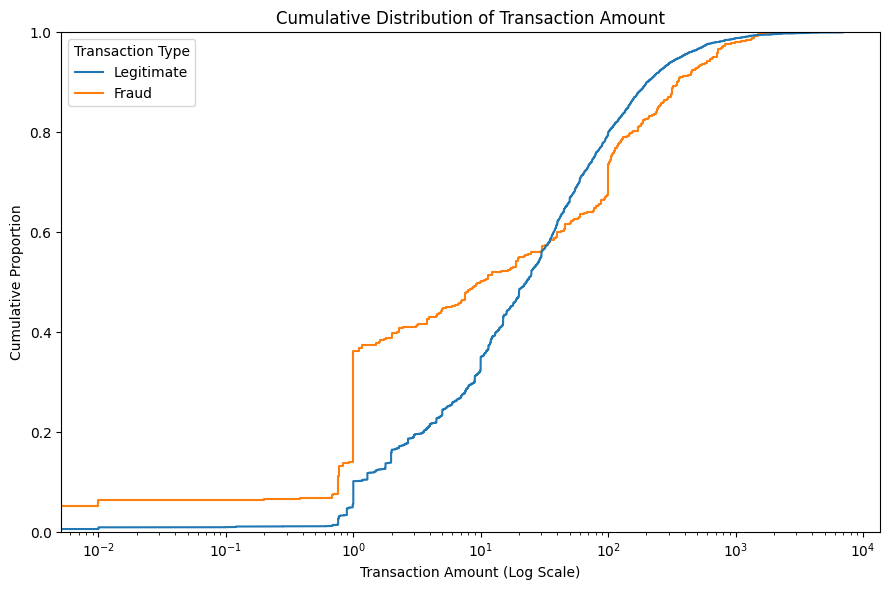

In [ ]:
#Ishita Plot 8- Fraud vs legitimate transaction amount ECDF


# Prepare plot_df by sampling legitimate transactions and getting all fraud cases
legit_sample = df[df["Class"] == 0].sample(n=5000, random_state=42)
fraud = df[df["Class"] == 1]
plot_df = pd.concat([legit_sample, fraud])

# Create human-readable transaction type labels
plot_df["Transaction Type"] = plot_df["Class"].map({
    0: "Legitimate",
    1: "Fraud"
})

plt.figure(figsize=(9, 6))

sns.ecdfplot(
    data=plot_df,
    x="Amount",
    hue="Transaction Type"
)

plt.xscale("log")
plt.title("Cumulative Distribution of Transaction Amount")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Cumulative Proportion")

plt.tight_layout()
plt.show()

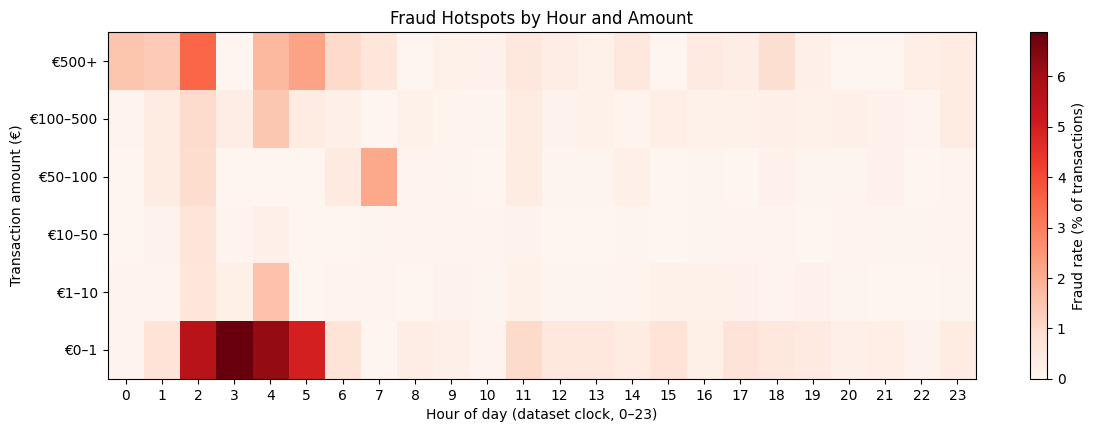

In [ ]:
# ULB: hour of day and amount groups ### Rahila plot1
df['Hour'] = (df['Time'] // 3600) % 24
df['AmountBand'] = pd.cut(df['Amount'], [-1, 1, 10, 50, 100, 500, 30000],
                          labels=['€0–1', '€1–10', '€10–50', '€50–100', '€100–500', '€500+'])

# ULB: fraud rate for every hour + amount combo
grid = df.pivot_table(index='AmountBand', columns='Hour', values='Class',
                      aggfunc='mean', observed=False) * 100

plt.figure(figsize=(14, 4.5))
plt.imshow(grid, cmap='Reds', aspect='auto', origin='lower')
plt.colorbar(label='Fraud rate (% of transactions)')
plt.yticks(range(len(grid.index)), grid.index)
plt.xticks(range(24))
plt.xlabel('Hour of day (dataset clock, 0–23)')
plt.ylabel('Transaction amount (€)')
plt.title('Fraud Hotspots by Hour and Amount')
plt.savefig('fig_hotspot.png', dpi=300, bbox_inches='tight')
plt.show()

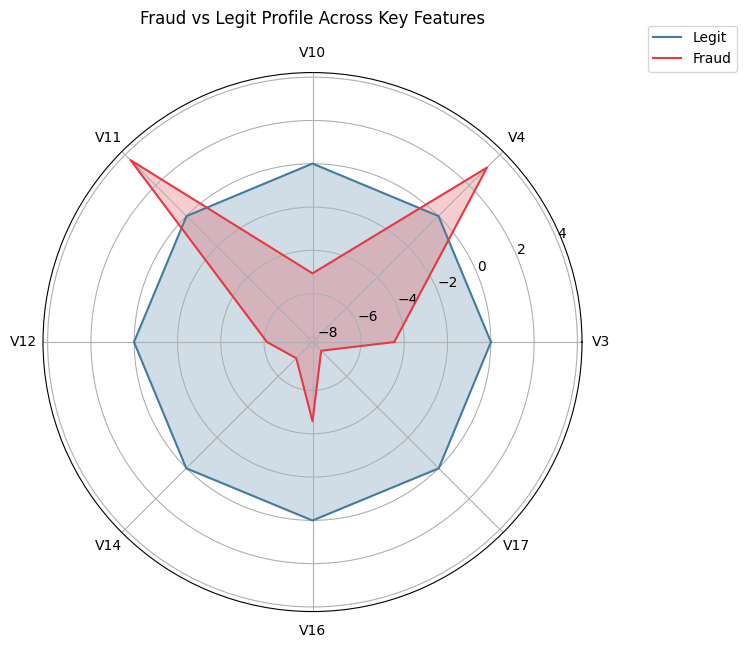

In [ ]:
# ULB: 8 features where fraud differs most ### Rahila plot2
features = ['V3', 'V4', 'V10', 'V11', 'V12', 'V14', 'V16', 'V17']

# ULB: put features on the same scale, then average for each class
z = (df[features] - df[features].mean()) / df[features].std()
legit = z[df['Class'] == 0].mean().tolist()
fraud = z[df['Class'] == 1].mean().tolist()

# close the circle
angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
legit += legit[:1]
fraud += fraud[:1]
angles += angles[:1]

plt.figure(figsize=(7, 7))
ax = plt.subplot(polar=True)
ax.plot(angles, legit, color="#457b9d", label='Legit')
ax.fill(angles, legit, color="#457b9d", alpha=0.25)
ax.plot(angles, fraud, color="#e63946", label='Fraud')
ax.fill(angles, fraud, color="#e63946", alpha=0.25)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(features)
plt.title('Fraud vs Legit Profile Across Key Features', pad=35)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.savefig('fig_radar.png', dpi=300, bbox_inches='tight')
plt.show()

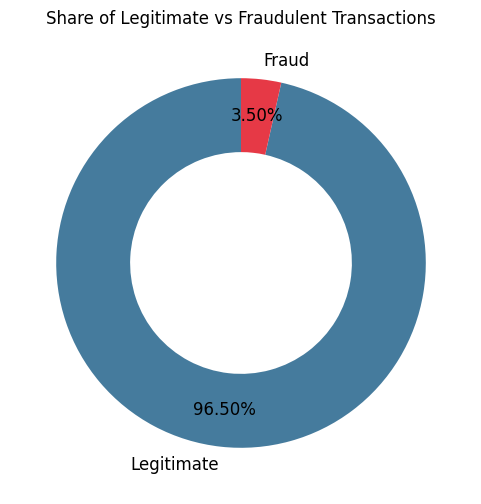

In [ ]:
# IEEE: how many legit vs fraud ###Rahila plot3
counts = ieee_clean['isFraud'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=['Legitimate', 'Fraud'], colors=["#457b9d", "#e63946"],
        autopct='%1.2f%%', startangle=90, pctdistance=0.8,
        wedgeprops={'width': 0.4}, textprops={'fontsize': 12})
plt.title('Share of Legitimate vs Fraudulent Transactions')
plt.savefig('fig_donut.png', dpi=300, bbox_inches='tight')
plt.show()

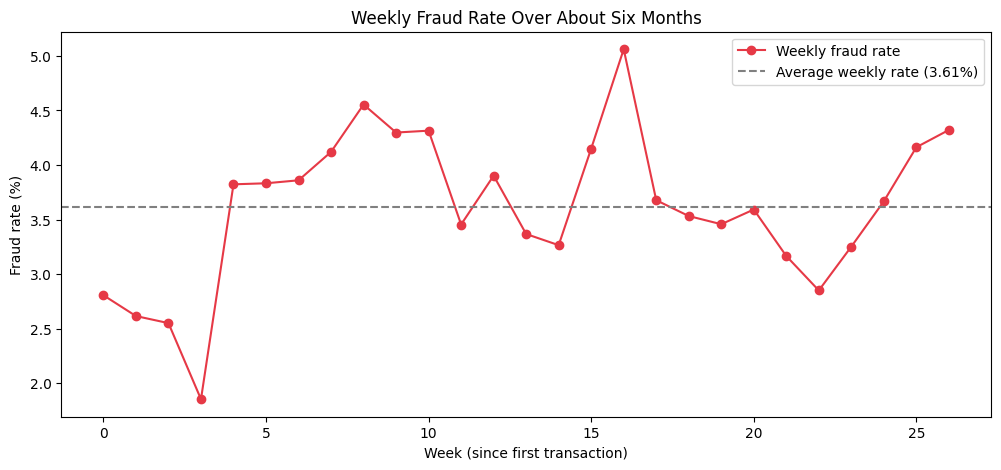

In [ ]:
# IEEE: turn seconds into weeks ### Rahila plot4
ieee_clean['Week'] = ieee_clean['TransactionDT'] // (7 * 86400)
weekly = ieee_clean.groupby('Week')['isFraud'].mean() * 100

plt.figure(figsize=(12, 5))
plt.plot(weekly.index, weekly.values, color="#e63946", marker='o', label='Weekly fraud rate')
plt.axhline(weekly.mean(), color='gray', linestyle='--', label=f'Average weekly rate ({weekly.mean():.2f}%)')
plt.xlabel('Week (since first transaction)')
plt.ylabel('Fraud rate (%)')
plt.title('Weekly Fraud Rate Over About Six Months')
plt.legend()
plt.savefig('fig_weekly.png', dpi=300, bbox_inches='tight')
plt.show()

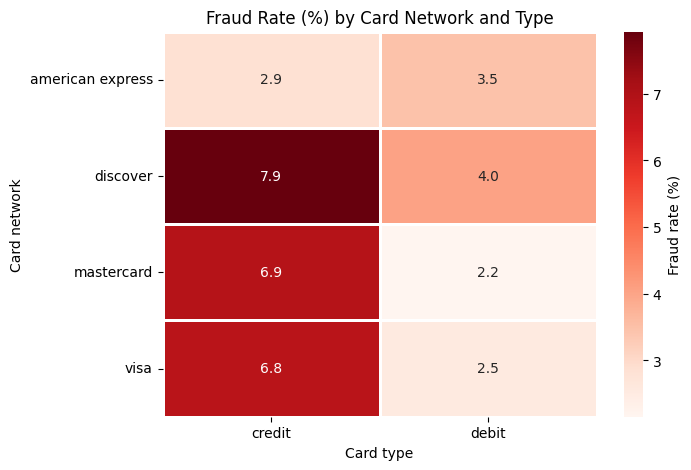

In [ ]:
# IEEE: keep only credit and debit  (Rahila 5)
cards = ieee_clean[ieee_clean['card6'].isin(['credit', 'debit'])]
table = cards.pivot_table(index='card4', columns='card6', values='isFraud', aggfunc='mean') * 100

plt.figure(figsize=(7, 5))
sns.heatmap(table, annot=True, fmt='.1f', cmap='Reds', linewidths=1, cbar_kws={'label': 'Fraud rate (%)'})
plt.title('Fraud Rate (%) by Card Network and Type')
plt.xlabel('Card type')
plt.ylabel('Card network')
plt.yticks(rotation=0)
plt.savefig('fig_cards.png', dpi=300, bbox_inches='tight')
plt.show()

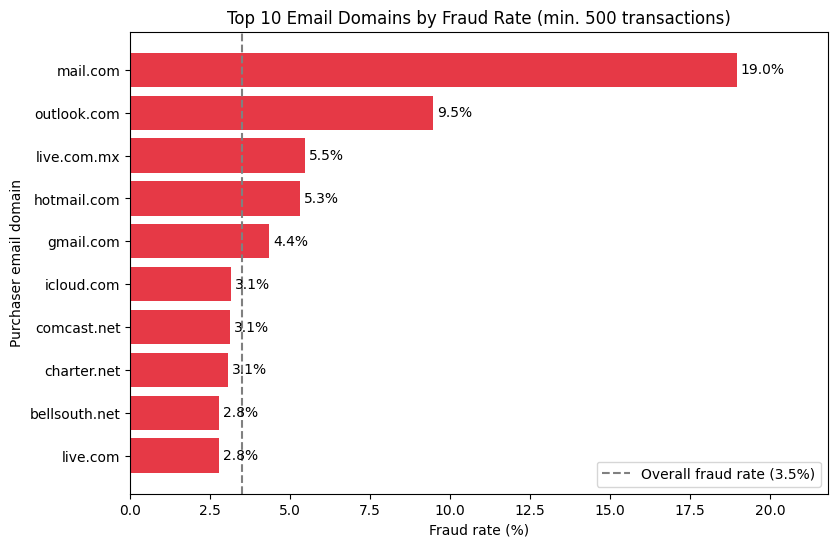

In [ ]:
# IEEE: fraud rate by email domain (Rahila plot6)
email = ieee_clean.groupby('P_emaildomain')['isFraud'].agg(['mean', 'count'])
email = email[email['count'] >= 500]
top = (email['mean'] * 100).sort_values().tail(10)

plt.figure(figsize=(9, 6))
bars = plt.barh(top.index, top.values, color="#e63946")
plt.bar_label(bars, fmt='%.1f%%', padding=3)
plt.axvline(ieee_clean['isFraud'].mean() * 100, color='gray', linestyle='--', label='Overall fraud rate (3.5%)')
plt.xlim(0, top.max() * 1.15)
plt.xlabel('Fraud rate (%)')
plt.ylabel('Purchaser email domain')
plt.title('Top 10 Email Domains by Fraud Rate (min. 500 transactions)')
plt.legend(loc='lower right')
plt.savefig('fig_email.png', dpi=300, bbox_inches='tight')
plt.show()

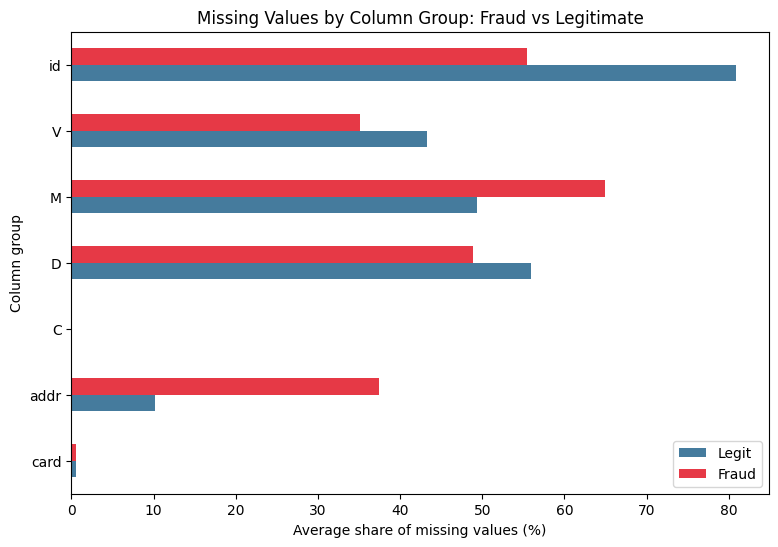

In [ ]:
# IEEE: the main groups of columns  (Rahila 7)
groups = {'card': '^card', 'addr': '^addr', 'C': r'^C\d', 'D': r'^D\d',
          'M': r'^M\d', 'V': r'^V\d', 'id': '^id_'}

# % missing in each group, for legit and fraud separately
missing = pd.DataFrame({
    name: ieee_clean.filter(regex=pat).isnull().mean(axis=1).groupby(ieee_clean['isFraud']).mean() * 100
    for name, pat in groups.items()}).T
missing.columns = ['Legit', 'Fraud']

missing.plot.barh(figsize=(9, 6), color=["#457b9d", "#e63946"])
plt.xlabel('Average share of missing values (%)')
plt.ylabel('Column group')
plt.title('Missing Values by Column Group: Fraud vs Legitimate')
plt.legend(loc='lower right')
plt.savefig('fig_missing.png', dpi=300, bbox_inches='tight')
plt.show()

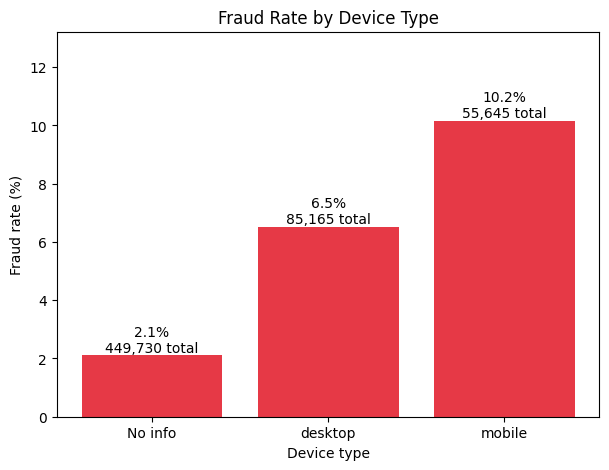

In [ ]:
# IEEE: device type, with "No info" when it's missing  (Rahila 8)
device = ieee_clean['DeviceType'].fillna('No info')
rate = ieee_clean.groupby(device)['isFraud'].mean() * 100
count = device.value_counts()

plt.figure(figsize=(7, 5))
bars = plt.bar(rate.index, rate.values, color="#e63946")
plt.bar_label(bars, labels=[f"{rate[d]:.1f}%\n{count[d]:,} total" for d in rate.index])
plt.ylim(0, rate.max() * 1.3)
plt.xlabel('Device type')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud Rate by Device Type')
plt.savefig('fig_device.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Plot 1: Transaction Amount × Product Type


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = ieee_clean.copy()

plot_df["Amount_Group"] = pd.qcut(
    plot_df["TransactionAmt"],
    q=5,
    labels=["Very Low", "Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

grouped = plot_df.groupby(
    ["ProductCD", "Amount_Group"],
    observed=True
)["isFraud"].agg(["mean", "count"]).reset_index()

# Exclude groups with fewer than 100 transactions
grouped.loc[grouped["count"] < 100, "mean"] = np.nan

heatmap_data = grouped.pivot(
    index="ProductCD",
    columns="Amount_Group",
    values="mean"
) * 100

plt.figure(figsize=(11, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={"label": "Fraud Rate (%)"}
)

plt.title("Fraud Risk by Amount and Product",
          fontsize=14, weight="bold")
plt.xlabel("Transaction Amount Quintile")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig("Fraud_Amount_Product.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [ ]:

# Plot 2: Transaction Distance by Fraud Status

plot_df = ieee_clean[
    ["dist1", "isFraud"]
].dropna().copy()

plot_df = plot_df[plot_df["dist1"] >= 0]

plot_df["Status"] = plot_df["isFraud"].map({
    0: "Legitimate",
    1: "Fraud"
})

# Log transform helps visualize skewed distances
plot_df["Log_Distance"] = np.log1p(plot_df["dist1"])

# Sample per group for efficient violin plotting
plot_df = (
    plot_df.groupby("Status", group_keys=False)
    .sample(
        n=10000,
        replace=True,
        random_state=42
    )
)

plt.figure(figsize=(9, 6))
sns.violinplot(
    data=plot_df,
    x="Status",
    y="Log_Distance",
    hue="Status",
    order=["Legitimate", "Fraud"],
    palette=["#457b9d", "#e63946"],
    inner="quart",
    cut=0,
    legend=False
)

plt.title("IEEE-CIS: Distance Distribution by Fraud Status",
          fontsize=14, weight="bold")
plt.xlabel("Transaction Status")
plt.ylabel("Log(1 + dist1)")
plt.tight_layout()
plt.show()


In [ ]:

# Plot 3: Fraud Rate by C1 Feature

plot_df = ieee_clean[["C1", "isFraud"]].dropna().copy()

# Group C1 into quantile-based bins
plot_df["C1_Group"] = pd.qcut(
    plot_df["C1"].rank(method="first"),
    q=8,
    labels=[f"G{i}" for i in range(1, 9)]
)

summary = plot_df.groupby(
    "C1_Group", observed=True
)["isFraud"].agg(
    Fraud_Rate="mean",
    Transactions="count"
).reset_index()

summary["Fraud_Rate"] *= 100

fig, ax = plt.subplots(figsize=(11, 6))

bars = sns.barplot(
    data=summary,
    x="C1_Group",
    y="Fraud_Rate",
    color="#e63946",
    ax=ax
)

for bar, total in zip(ax.patches, summary["Transactions"]):
    ax.annotate(
        f"n={total:,}",
        (bar.get_x() + bar.get_width()/2,
         bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, summary["Fraud_Rate"].max() * 1.25)
ax.set_title("Fraud Rate Across C1 Feature Groups",
             fontsize=14, weight="bold")
ax.set_xlabel("C1 Feature Group (Low to High)")
ax.set_ylabel("Fraud Rate (%)")
plt.tight_layout()

plt.savefig("C1_Fraud_Rate.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

# Plot 4: Fraud Rate by Card Identifier Frequency

plot_df = ieee_clean[
    ["card1", "isFraud"]
].dropna().copy()

# Count occurrences of each identifier value
card_counts = plot_df["card1"].value_counts()
plot_df["Card_Frequency"] = plot_df["card1"].map(card_counts)

# Quantile-based frequency groups
plot_df["Frequency_Group"] = pd.qcut(
    plot_df["Card_Frequency"].rank(method="first"),
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

summary = plot_df.groupby(
    "Frequency_Group", observed=True
)["isFraud"].agg(["mean", "count"]).reset_index()

summary["Fraud_Rate"] = summary["mean"] * 100

# Approximate 95% confidence intervals
p = summary["mean"]
n = summary["count"]

summary["CI"] = (
    1.96 * np.sqrt(p * (1 - p) / n) * 100
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    summary["Frequency_Group"].astype(str),
    summary["Fraud_Rate"],
    yerr=summary["CI"],
    fmt="o-",
    color="#e63946",
    linewidth=2.5,
    capsize=5,
    markersize=8
)

plt.title(
    "Fraud Risk by Card Identifier Frequency",
    fontsize=14,
    weight="bold"
)
plt.xlabel("Frequency Quintile (Low to High)")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.savefig("Card_Frequency_Risk.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

# Plot 5: Fraud Capture and False Positive Trade-off

plot_df = ieee_clean[
    ["TransactionAmt", "isFraud"]
].dropna().copy()

thresholds = np.percentile(
    plot_df["TransactionAmt"],
    np.linspace(50, 99, 40)
)

results = []

for threshold in thresholds:
    predicted = plot_df["TransactionAmt"] >= threshold
    actual = plot_df["isFraud"] == 1

    tp = (predicted & actual).sum()
    fp = (predicted & ~actual).sum()
    fn = (~predicted & actual).sum()
    tn = (~predicted & ~actual).sum()

    recall = tp / (tp + fn) if tp + fn else 0
    fpr = fp / (fp + tn) if fp + tn else 0

    results.append([threshold, recall * 100, fpr * 100])

results = pd.DataFrame(
    results,
    columns=["Threshold", "Fraud_Capture", "False_Positive_Rate"]
)

plt.figure(figsize=(11, 6))

plt.plot(
    results["Threshold"],
    results["Fraud_Capture"],
    label="Fraud Capture Rate (Recall)",
    color="#e63946",
    linewidth=2.5
)

plt.plot(
    results["Threshold"],
    results["False_Positive_Rate"],
    label="False Positive Rate",
    color="#457b9d",
    linewidth=2.5
)

plt.title(
    "Fraud Capture vs. False Positive Trade-off",
    fontsize=14,
    weight="bold"
)
plt.xlabel("Transaction Amount Alert Threshold")
plt.ylabel("Percentage (%)")
plt.legend()
plt.tight_layout()
plt.savefig("Fraud_Tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

